
# 🧹 DATA CLEANING & PREPROCESSING

<div style="background-color:#e8f5e9; padding:12px; border-radius:8px;">
<b>🎯 Objective:</b> Prepare reliable datasets for predicting agricultural residue-burning activity across districts of Punjab and Haryana.
</div>

## 📌 Project Research Direction

**Primary target:** CREAMS district-level daily burning counts (`fires_day`).

**Supporting datasets:**
- FIRMS satellite fire detections
- Paddy cultivation area and production
- MODIS burned-area observations
- Geographic district boundaries

## 🛠️ Cleaning Workflow

1. Load raw datasets.
2. Preserve original data.
3. Handle missing observations carefully.
4. Investigate suspicious records.
5. Standardize column names and data types.
6. Validate geographic and temporal consistency.
7. Save cleaned datasets separately.

⚠️ **Important:** Missing values will not automatically be replaced with zero, and suspicious observations will not be deleted without evidence.


In [1]:

# Import essential libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import json

# Display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Define project directories

RAW_DIR = "../Data/Raw_data"
PROCESSED_DIR = "../Data/processed_data"

# Create processed directory if it does not exist

os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Raw data directory:", os.path.abspath(RAW_DIR))
print("Processed data directory:", os.path.abspath(PROCESSED_DIR))

print("\nRaw directory exists:", os.path.exists(RAW_DIR))
print("Processed directory exists:", os.path.exists(PROCESSED_DIR))


Raw data directory: c:\Users\kenpa\OneDrive\Desktop\INT_324_Project\Data\Raw_data
Processed data directory: c:\Users\kenpa\OneDrive\Desktop\INT_324_Project\Data\processed_data

Raw directory exists: True
Processed directory exists: True



## 🌾 2. LOAD THE PRIMARY CREAMS DATASET

**Dataset:** `district_daily.csv`

**Purpose:** This dataset contains district-level daily agricultural residue-burning observations.

**Primary target variable:** `fires_day`

We will preserve the original dataset in `creams_daily_raw` and perform all cleaning operations on a separate working copy.

⚠️ The original data must remain unchanged throughout preprocessing.


In [3]:

# Load the original CREAMS dataset

creams_daily_raw = pd.read_csv(
    "../Data/Raw_data/CREAMS/district_daily.csv"
)

# Create a separate working copy

creams_daily_clean = creams_daily_raw.copy()

# Inspect the dataset

print("Original dataset shape:", creams_daily_raw.shape)
print("Working copy shape:", creams_daily_clean.shape)

print("\nCOLUMN NAMES:")
print(creams_daily_clean.columns.tolist())

print("\nFIRST FIVE RECORDS:")
display(creams_daily_clean.head())

print("\nDATA TYPES:")
print(creams_daily_clean.dtypes)


Original dataset shape: (198423, 13)
Working copy shape: (198423, 13)

COLUMN NAMES:
['date', 'season', 'season_year', 'state', 'district', 'fires_day', 'fires_cumulative', 'cum_period_start', 'day_source', 'cum_source', 'cum_check', 'bulletin_file', 'cum_bulletin_file']

FIRST FIVE RECORDS:


,date,season,season_year,state,district,fires_day,fires_cumulative,cum_period_start,day_source,cum_source,cum_check,bulletin_file,cum_bulletin_file
0,2016-10-01,rice,2016,Punjab,Amritsar,NaN,48.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
1,2016-10-01,rice,2016,Punjab,Barnala,NaN,0.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
2,2016-10-01,rice,2016,Punjab,Bathinda,NaN,3.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
3,2016-10-01,rice,2016,Punjab,Faridkot,NaN,2.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf
4,2016-10-01,rice,2016,Punjab,Fatehgarh Sahib,NaN,0.0,2016-10-01,NaN,district_table,sum_ok,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf,01.RiceResidueFireBulletin_01Oct_2020_ICAR.pdf



DATA TYPES:
date                  object
season                object
season_year            int64
state                 object
district              object
fires_day            float64
fires_cumulative     float64
cum_period_start      object
day_source            object
cum_source            object
cum_check             object
bulletin_file         object
cum_bulletin_file     object
dtype: object


In [4]:

# Convert date columns into datetime format

creams_daily_clean["date"] = pd.to_datetime(
    creams_daily_clean["date"],
    errors="coerce"
)

creams_daily_clean["cum_period_start"] = pd.to_datetime(
    creams_daily_clean["cum_period_start"],
    errors="coerce"
)

# Verify updated data types

print("UPDATED DATA TYPES:")
print(creams_daily_clean.dtypes)

# Check invalid dates introduced during conversion

print("\nINVALID DATE VALUES:")

print(
    "date:",
    creams_daily_clean["date"].isna().sum()
)

print(
    "cum_period_start:",
    creams_daily_clean["cum_period_start"].isna().sum()
)

# Check date range

print("\nOBSERVATION DATE RANGE:")
print("Earliest:", creams_daily_clean["date"].min())
print("Latest:", creams_daily_clean["date"].max())

print("\nCUMULATIVE PERIOD RANGE:")
print("Earliest:", creams_daily_clean["cum_period_start"].min())
print("Latest:", creams_daily_clean["cum_period_start"].max())


UPDATED DATA TYPES:
date                 datetime64[ns]
season                       object
season_year                   int64
state                        object
district                     object
fires_day                   float64
fires_cumulative            float64
cum_period_start     datetime64[ns]
day_source                   object
cum_source                   object
cum_check                    object
bulletin_file                object
cum_bulletin_file            object
dtype: object

INVALID DATE VALUES:
date: 0
cum_period_start: 61

OBSERVATION DATE RANGE:
Earliest: 2016-10-01 00:00:00
Latest: 2026-10-27 00:00:00

CUMULATIVE PERIOD RANGE:
Earliest: 2016-10-01 00:00:00
Latest: 2026-09-15 00:00:00



## 📅 4. TEMPORAL CONSISTENCY VALIDATION

**Objective:** Verify the logical consistency of observation dates, season labels and season years.

Checks:
- Valid season categories.
- Observation year versus season year.
- Cumulative period start versus observation date.
- Missing or suspicious temporal information.

⚠️ Any inconsistency will be investigated before records are modified or removed.


In [5]:

# 1. Check unique season labels

print("UNIQUE SEASONS:")
print(creams_daily_clean["season"].unique())

print("\nSEASON DISTRIBUTION:")
display(creams_daily_clean["season"].value_counts(dropna=False))


# 2. Check whether season_year matches date year

year_mismatch = creams_daily_clean[
    creams_daily_clean["date"].dt.year
    != creams_daily_clean["season_year"]
]

print("\nDATE YEAR VS SEASON YEAR")
print("Total mismatches:", len(year_mismatch))

display(
    year_mismatch[
        ["date", "season", "season_year", "state", "district"]
    ].head(15)
)


# 3. Check cumulative period start

period_mismatch = creams_daily_clean[
    creams_daily_clean["cum_period_start"].notna()
    &
    (
        creams_daily_clean["cum_period_start"]
        > creams_daily_clean["date"]
    )
]

print("\nCUMULATIVE PERIOD START AFTER OBSERVATION DATE:")
print("Total mismatches:", len(period_mismatch))

display(
    period_mismatch[
        [
            "date",
            "season",
            "season_year",
            "cum_period_start",
            "state",
            "district"
        ]
    ].head(15)
)


# 4. Check valid season categories

valid_seasons = ["rice", "wheat"]

invalid_seasons = creams_daily_clean[
    ~creams_daily_clean["season"].isin(valid_seasons)
]

print("\nINVALID SEASON LABELS:")
print("Total:", len(invalid_seasons))

display(invalid_seasons.head(10))


# 5. Check date and season-year ranges

print("\nSEASON YEAR RANGE:")
print(
    creams_daily_clean["season_year"].min(),
    "to",
    creams_daily_clean["season_year"].max()
)

print("\nOBSERVATION DATE RANGE:")
print(
    creams_daily_clean["date"].min(),
    "to",
    creams_daily_clean["date"].max()
)


# 6. Summarize temporal coverage

print("\nRECORD COUNTS BY SEASON AND YEAR:")

display(
    creams_daily_clean.groupby(
        ["season_year", "season"]
    ).size().unstack(fill_value=0)
)


UNIQUE SEASONS:
['rice' 'wheat']

SEASON DISTRIBUTION:


season
rice     143019
wheat     55404
Name: count, dtype: int64


DATE YEAR VS SEASON YEAR
Total mismatches: 0


,date,season,season_year,state,district



CUMULATIVE PERIOD START AFTER OBSERVATION DATE:
Total mismatches: 0


,date,season,season_year,cum_period_start,state,district



INVALID SEASON LABELS:
Total: 0


,date,season,season_year,state,district,fires_day,fires_cumulative,cum_period_start,day_source,cum_source,cum_check,bulletin_file,cum_bulletin_file



SEASON YEAR RANGE:
2016 to 2026

OBSERVATION DATE RANGE:
2016-10-01 00:00:00 to 2026-10-27 00:00:00

RECORD COUNTS BY SEASON AND YEAR:


season,rice,wheat
season_year,,
2016,7197,0
2017,7218,0
2018,7265,0
2019,7272,0
2020,17400,0
2021,17339,0
2022,17338,11107
2023,17338,11095
2024,17338,11077



## 🔍 5. DUPLICATE RECORD VALIDATION

**Objective:** Verify that each district has only one observation per date and season.

We will check:
- Exact duplicate rows.
- Duplicate date-season-state-district combinations.
- Which records are duplicated, if any.

⚠️ Duplicate records will be investigated before removal. We will not automatically delete them.


In [6]:

# 1. Check exact duplicate rows

exact_duplicates = creams_daily_clean.duplicated()

print("EXACT DUPLICATE ROWS:", exact_duplicates.sum())


# 2. Define the logical key for one district-day observation

key_columns = [
    "date",
    "season",
    "season_year",
    "state",
    "district"
]


# 3. Check duplicate logical keys

logical_duplicates = creams_daily_clean.duplicated(
    subset=key_columns,
    keep=False
)

duplicate_records = creams_daily_clean[
    logical_duplicates
].sort_values(key_columns)

print("\nDUPLICATE DISTRICT-DATE-SEASON RECORDS:")
print("Total affected rows:", len(duplicate_records))

display(duplicate_records.head(20))


# 4. Count duplicated keys separately

duplicate_key_count = (
    creams_daily_clean.loc[logical_duplicates, key_columns]
    .drop_duplicates()
    .shape[0]
)

print("\nNUMBER OF DUPLICATED LOGICAL KEYS:", duplicate_key_count)


# 5. Verify missing values in key columns

print("\nMISSING VALUES IN LOGICAL KEY COLUMNS:")

display(
    creams_daily_clean[key_columns].isnull().sum()
)


EXACT DUPLICATE ROWS: 0

DUPLICATE DISTRICT-DATE-SEASON RECORDS:
Total affected rows: 0


,date,season,season_year,state,district,fires_day,fires_cumulative,cum_period_start,day_source,cum_source,cum_check,bulletin_file,cum_bulletin_file



NUMBER OF DUPLICATED LOGICAL KEYS: 0

MISSING VALUES IN LOGICAL KEY COLUMNS:


date           0
season         0
season_year    0
state          0
district       0
dtype: int64


## 🎯 6. TARGET VARIABLE ANALYSIS — FIRES_DAY

**Objective:** Understand the availability, distribution and reliability of our prediction target.

We will investigate:
- Available versus missing daily counts.
- Daily count distribution.
- Zero and positive observations.
- Negative values.
- Target availability across seasons and years.

⚠️ Missing daily counts will not be treated as zero. Missing means unavailable, not necessarily zero burning activity.


In [7]:

# 1. Target availability

print("TOTAL RECORDS:", len(creams_daily_clean))

print("\nMISSING FIRES_DAY:")
print(creams_daily_clean["fires_day"].isna().sum())

print("\nAVAILABLE FIRES_DAY:")
print(creams_daily_clean["fires_day"].notna().sum())

print("\nTARGET AVAILABILITY (%):")
print(
    creams_daily_clean["fires_day"].notna().mean() * 100
)


# 2. Descriptive statistics of available target values

print("\nFIRES_DAY STATISTICS:")

display(
    creams_daily_clean["fires_day"].describe()
)


# 3. Zero, positive and negative values

available_target = creams_daily_clean["fires_day"].dropna()

print("\nZERO COUNTS:", (available_target == 0).sum())

print("POSITIVE COUNTS:", (available_target > 0).sum())

print("NEGATIVE COUNTS:", (available_target < 0).sum())


# 4. Target availability by season and year

target_availability = (
    creams_daily_clean
    .groupby(["season_year", "season"])
    ["fires_day"]
    .agg(
        total_records="size",
        available="count",
        missing=lambda x: x.isna().sum()
    )
)

target_availability["availability_pct"] = (
    target_availability["available"]
    / target_availability["total_records"]
    * 100
)

print("\nTARGET AVAILABILITY BY SEASON AND YEAR:")

display(target_availability.round(2))


TOTAL RECORDS: 198423

MISSING FIRES_DAY:
155894

AVAILABLE FIRES_DAY:
42529

TARGET AVAILABILITY (%):
21.433503172515284

FIRES_DAY STATISTICS:


count    42529.000000
mean        16.461991
std         47.407685
min          1.000000
25%          1.000000
50%          3.000000
75%         10.000000
max        893.000000
Name: fires_day, dtype: float64


ZERO COUNTS: 0
POSITIVE COUNTS: 42529
NEGATIVE COUNTS: 0

TARGET AVAILABILITY BY SEASON AND YEAR:


total_records  available  missing  availability_pct
season_year season                                                     
2016        rice             7197          0     7197              0.00
2017        rice             7218          0     7218              0.00
2018        rice             7265       2786     4479             38.35
2019        rice             7272       2166     5106             29.79
2020        rice            17400       3313    14087             19.04
2021        rice            17339       3682    13657             21.24
2022        rice            17338       3551    13787             20.48
            wheat           11107       3258     7849             29.33
2023        rice            17338       4041    13297             23.31
            wheat           11095       3034     8061             27.35
2024        rice            17338       4025    13313             23.21
            wheat           11077          0    11077              0.00
2025        rice            17338       3778    13560             21.79
            wheat           11083       3294     7789             29.72
2026        rice             9976        732     9244              7.34
            wheat           11042       4869     6173             44.10


## 📊 7. TEMPORAL AND GEOGRAPHIC COVERAGE OF THE TARGET

**Objective:** Determine whether available daily burning counts cover enough years and districts for reliable model training.

We will examine:
- Complete target availability across all season-years.
- Number of districts with available target observations.
- Number of observation dates with available target counts.

This helps us assess whether the data supports chronological model evaluation and district-level generalization.


In [8]:

# 1. Print the complete availability table

print("COMPLETE TARGET AVAILABILITY:")

print(target_availability.round(2).to_string())


# 2. Geographic coverage of available target observations

available_rows = creams_daily_clean[
    creams_daily_clean["fires_day"].notna()
].copy()

district_coverage = (
    available_rows
    .groupby(["season_year", "season"])
    .agg(
        available_records=("fires_day", "count"),
        unique_districts=("district", "nunique"),
        unique_states=("state", "nunique"),
        unique_dates=("date", "nunique")
    )
)

print("\nGEOGRAPHIC AND TEMPORAL COVERAGE:")

print(district_coverage.to_string())


# 3. Overall geographic coverage

print("\nOVERALL TARGET COVERAGE:")

print(
    "Unique districts:",
    available_rows["district"].nunique()
)

print(
    "Unique states:",
    available_rows["state"].nunique()
)

print(
    "Unique observation dates:",
    available_rows["date"].nunique()
)

print(
    "Earliest available target date:",
    available_rows["date"].min()
)

print(
    "Latest available target date:",
    available_rows["date"].max()
)


COMPLETE TARGET AVAILABILITY:
                    total_records  available  missing  availability_pct
season_year season                                                     
2016        rice             7197          0     7197              0.00
2017        rice             7218          0     7218              0.00
2018        rice             7265       2786     4479             38.35
2019        rice             7272       2166     5106             29.79
2020        rice            17400       3313    14087             19.04
2021        rice            17339       3682    13657             21.24
2022        rice            17338       3551    13787             20.48
            wheat           11107       3258     7849             29.33
2023        rice            17338       4041    13297             23.31
            wheat           11095       3034     8061             27.35
2024        rice            17338       4025    13313             23.21
            wheat           11077 


## 🗺️ 8. PUNJAB AND HARYANA TARGET COVERAGE

**Objective:** Evaluate the availability of daily burning counts within our intended research geography.

We will examine:
- Target availability by state, season and year.
- Number of districts represented.
- Number of dates with recorded daily counts.
- District-level coverage across the study period.

This will help us decide whether Punjab and Haryana provide a sufficiently reliable modelling dataset.


In [9]:

# 1. Filter Punjab and Haryana

target_states = ["Punjab", "Haryana"]

ph_data = creams_daily_clean[
    creams_daily_clean["state"].isin(target_states)
].copy()

ph_available = ph_data[
    ph_data["fires_day"].notna()
].copy()


# 2. Availability by state, season and year

state_year_coverage = (
    ph_data
    .groupby(["state", "season_year", "season"])
    .agg(
        total_records=("fires_day", "size"),
        available=("fires_day", "count"),
        missing=("fires_day", lambda x: x.isna().sum()),
        districts=("district", "nunique")
    )
)

state_year_coverage["availability_pct"] = (
    state_year_coverage["available"]
    / state_year_coverage["total_records"]
    * 100
)

print("PUNJAB AND HARYANA — TARGET AVAILABILITY")

print(state_year_coverage.round(2).to_string())


# 3. Geographic coverage of available observations

geographic_coverage = (
    ph_available
    .groupby(["state", "season_year", "season"])
    .agg(
        available_records=("fires_day", "count"),
        unique_districts=("district", "nunique"),
        unique_dates=("date", "nunique")
    )
)

print("\nAVAILABLE TARGET — DISTRICT AND DATE COVERAGE")

print(geographic_coverage.to_string())


# 4. Overall coverage

print("\nOVERALL PUNJAB AND HARYANA COVERAGE")

print("Total records:", len(ph_data))
print("Available target records:", len(ph_available))
print("Unique districts in dataset:", ph_data["district"].nunique())
print("Unique districts with target:", ph_available["district"].nunique())
print("Unique dates with target:", ph_available["date"].nunique())

print("\nSTATE-WISE DISTRICT COVERAGE")

print(
    ph_available.groupby("state")["district"].nunique()
)


PUNJAB AND HARYANA — TARGET AVAILABILITY
                            total_records  available  missing  districts  availability_pct
state   season_year season                                                                
Haryana 2016        rice             1339          0     1339         24              0.00
        2017        rice             1339          0     1339         24              0.00
        2018        rice             1340        588      752         24             43.88
        2019        rice             1339        445      894         24             33.23
        2020        rice             1782        621     1161         26             34.85
        2021        rice             1780        548     1232         24             30.79
        2022        rice             1780        501     1279         24             28.15
                    wheat            1342        314     1028         22             23.40
        2023        rice             1780        


## 🏘️ 9. DISTRICT-LEVEL TARGET COVERAGE

**Objective:** Understand how evenly available daily burning observations are distributed across districts.

We will calculate:
- Available target records per district.
- Number of distinct observation dates per district.
- First and last available observation dates.
- Number of rice and wheat observations per district.

⚠️ A district with very few observations may not be suitable for reliable model training or evaluation.


In [10]:

# 1. District-level coverage

district_target_coverage = (
    ph_available
    .groupby(["state", "district"])
    .agg(
        available_records=("fires_day", "count"),
        unique_dates=("date", "nunique"),
        rice_records=(
            "season",
            lambda x: (x == "rice").sum()
        ),
        wheat_records=(
            "season",
            lambda x: (x == "wheat").sum()
        ),
        first_observation=("date", "min"),
        last_observation=("date", "max")
    )
    .reset_index()
    .sort_values(
        ["state", "available_records"],
        ascending=[True, False]
    )
)

print("DISTRICT-LEVEL TARGET COVERAGE:")

display(district_target_coverage)


# 2. Summary statistics by state

print("\nCOVERAGE SUMMARY BY STATE:")

display(
    district_target_coverage
    .groupby("state")
    .agg(
        districts=("district", "nunique"),
        total_records=("available_records", "sum"),
        median_records=("available_records", "median"),
        minimum_records=("available_records", "min"),
        maximum_records=("available_records", "max"),
        median_dates=("unique_dates", "median")
    )
)


# 3. Districts with the fewest available observations

print("\n10 DISTRICTS WITH THE FEWEST AVAILABLE RECORDS:")

display(
    district_target_coverage
    .sort_values("available_records")
    .head(10)
)


# 4. Districts with the most available observations

print("\n10 DISTRICTS WITH THE MOST AVAILABLE RECORDS:")

display(
    district_target_coverage
    .sort_values("available_records", ascending=False)
    .head(10)
)


DISTRICT-LEVEL TARGET COVERAGE:


,state,district,available_records,unique_dates,rice_records,wheat_records,first_observation,last_observation
4,Haryana,Fatehabad,453,453,371,82,2018-10-06,2026-05-25
9,Haryana,Jind,452,452,370,82,2018-10-06,2026-10-24
10,Haryana,Kaithal,441,441,351,90,2018-10-02,2026-10-24
11,Haryana,Karnal,416,416,330,86,2018-10-01,2026-10-25
20,Haryana,Sirsa,415,415,322,93,2018-10-04,2026-10-14
7,Haryana,Hisar,364,364,287,77,2018-10-01,2026-10-18
0,Haryana,Ambala,358,358,290,68,2018-10-01,2026-05-24
21,Haryana,Sonipat,344,344,242,102,2018-10-02,2026-10-09
12,Haryana,Kurukshetra,342,342,275,67,2018-10-01,2026-10-22
22,Haryana,Yamunanagar,320,320,267,53,2018-10-01,2026-10-26



COVERAGE SUMMARY BY STATE:


,districts,total_records,median_records,minimum_records,maximum_records,median_dates
state,,,,,,
Haryana,23,5209,242.0,1,453,242.0
Punjab,25,9185,426.0,1,558,426.0



10 DISTRICTS WITH THE FEWEST AVAILABLE RECORDS:


,state,district,available_records,unique_dates,rice_records,wheat_records,first_observation,last_observation
6,Haryana,Hansi,1,1,1,0,2026-09-30,2026-09-30
41,Punjab,Punjab,1,1,0,1,2026-05-12,2026-05-12
34,Punjab,Kharar,1,1,1,0,2021-10-20,2021-10-20
13,Haryana,Mahendragarh,4,4,4,0,2018-10-06,2020-11-04
18,Haryana,Rewari,12,12,5,7,2019-10-15,2026-04-27
14,Haryana,Nuh,21,21,5,16,2018-10-06,2026-05-30
5,Haryana,Gurugram,32,32,7,25,2019-10-24,2026-05-27
2,Haryana,Charkhi Dadri,37,37,8,29,2020-10-27,2026-05-13
16,Haryana,Panchkula,45,45,38,7,2018-10-06,2026-09-23
39,Punjab,Pathankot,90,90,26,64,2019-10-27,2026-10-26



10 DISTRICTS WITH THE MOST AVAILABLE RECORDS:


,state,district,available_records,unique_dates,rice_records,wheat_records,first_observation,last_observation
23,Punjab,Amritsar,558,558,463,95,2018-10-01,2026-10-27
29,Punjab,Firozpur,531,531,416,115,2018-10-01,2026-10-27
47,Punjab,Tarn Taran,530,530,442,88,2018-10-02,2026-10-27
40,Punjab,Patiala,509,509,396,113,2018-10-04,2026-10-26
35,Punjab,Ludhiana,487,487,376,111,2018-10-04,2026-10-17
45,Punjab,Sangrur,483,483,379,104,2018-10-05,2026-10-27
32,Punjab,Jalandhar,471,471,363,108,2018-10-12,2026-10-27
33,Punjab,Kapurthala,470,470,363,107,2018-10-07,2026-10-27
4,Haryana,Fatehabad,453,453,371,82,2018-10-06,2026-05-25
9,Haryana,Jind,452,452,370,82,2018-10-06,2026-10-24



## 📆 10. OBSERVATION GAP AND DISTRICT NAME VALIDATION

**Objective:** Check whether daily target observations form usable time sequences.

We will:
- Calculate gaps between consecutive available observation dates.
- Summarize median and maximum gaps by district and season-year.
- Identify districts with large gaps.
- Inspect suspicious district labels such as Punjab and Kharar.

⚠️ Missing observation dates will not be interpreted as zero-fire days.


In [11]:

# 1. Calculate gaps between available observations
# Keep each season-year separate to avoid mixing different seasons.

def calculate_date_gaps(group):

    dates = (
        group["date"]
        .drop_duplicates()
        .sort_values()
    )

    gaps = dates.diff().dt.days.dropna()

    return pd.Series({
        "available_dates": len(dates),
        "median_gap_days": gaps.median() if len(gaps) else None,
        "maximum_gap_days": gaps.max() if len(gaps) else None,
        "gaps_over_3_days": (gaps > 3).sum(),
        "gaps_over_7_days": (gaps > 7).sum()
    })


district_gap_analysis = (
    ph_available
    .groupby(["state", "district", "season_year", "season"])
    .apply(calculate_date_gaps)
    .reset_index()
)

print("OBSERVATION GAP ANALYSIS:")

display(district_gap_analysis.head(20))


# 2. Find district-season-years with the largest gaps

print("\nLARGEST OBSERVATION GAPS:")

display(
    district_gap_analysis
    .sort_values("maximum_gap_days", ascending=False)
    .head(20)
)


# 3. Overall gap summary

print("\nOVERALL GAP SUMMARY:")

display(
    district_gap_analysis[
        [
            "median_gap_days",
            "maximum_gap_days",
            "gaps_over_3_days",
            "gaps_over_7_days"
        ]
    ].describe()
)


# 4. Inspect suspicious district labels

print("\nSUSPICIOUS DISTRICT LABELS:")

suspicious_districts = ph_data[
    ph_data["district"].isin(["Punjab", "Kharar"])
]

display(
    suspicious_districts[
        [
            "date",
            "season",
            "season_year",
            "state",
            "district",
            "fires_day",
            "fires_cumulative",
            "bulletin_file"
        ]
    ]
)


OBSERVATION GAP ANALYSIS:


C:\Users\kenpa\AppData\Local\Temp\ipykernel_428\3373097814.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_date_gaps)


,state,district,season_year,season,available_dates,median_gap_days,maximum_gap_days,gaps_over_3_days,gaps_over_7_days
0,Haryana,Ambala,2018,rice,46.0,1.0,5.0,1.0,0.0
1,Haryana,Ambala,2019,rice,34.0,1.0,7.0,4.0,0.0
2,Haryana,Ambala,2020,rice,47.0,1.0,3.0,0.0,0.0
3,Haryana,Ambala,2021,rice,43.0,1.0,4.0,1.0,0.0
4,Haryana,Ambala,2022,rice,42.0,1.0,6.0,2.0,0.0
5,Haryana,Ambala,2022,wheat,18.0,1.0,5.0,1.0,0.0
6,Haryana,Ambala,2023,rice,39.0,1.0,9.0,2.0,2.0
7,Haryana,Ambala,2023,wheat,16.0,1.0,10.0,4.0,2.0
8,Haryana,Ambala,2024,rice,32.0,1.0,9.0,6.0,1.0
9,Haryana,Ambala,2025,rice,7.0,3.5,22.0,3.0,1.0



LARGEST OBSERVATION GAPS:


,state,district,season_year,season,available_dates,median_gap_days,maximum_gap_days,gaps_over_3_days,gaps_over_7_days
34,Haryana,Faridabad,2020,rice,3.0,21.0,39.0,1.0,1.0
489,Punjab,SBS Nagar,2026,rice,2.0,37.0,37.0,1.0,1.0
141,Haryana,Mahendragarh,2019,rice,2.0,34.0,34.0,1.0,1.0
355,Punjab,Hoshiarpur,2026,rice,4.0,2.0,34.0,1.0,1.0
399,Punjab,Malerkotla,2025,rice,23.0,1.0,31.0,3.0,1.0
196,Haryana,Rohtak,2023,rice,24.0,1.0,30.0,3.0,1.0
77,Haryana,Jhajjar,2019,rice,4.0,12.0,29.0,3.0,2.0
485,Punjab,SBS Nagar,2023,wheat,18.0,1.0,29.0,2.0,1.0
353,Punjab,Hoshiarpur,2025,rice,10.0,3.0,29.0,4.0,4.0
186,Haryana,Rewari,2020,rice,2.0,29.0,29.0,1.0,1.0



OVERALL GAP SUMMARY:


,median_gap_days,maximum_gap_days,gaps_over_3_days,gaps_over_7_days
count,502.000000,502.000000,530.000000,530.000000
mean,2.008964,8.494024,1.828302,0.492453
std,3.691229,6.175006,1.348089,0.733314
min,1.000000,2.000000,0.000000,0.000000
25%,1.000000,5.000000,1.000000,0.000000
50%,1.000000,6.000000,2.000000,0.000000
75%,1.000000,10.000000,3.000000,1.000000
max,37.000000,39.000000,7.000000,4.000000



SUSPICIOUS DISTRICT LABELS:


,date,season,season_year,state,district,fires_day,fires_cumulative,bulletin_file
54553,2021-10-20,rice,2021,Punjab,Kharar,1.0,NaN,36.RiceResidueFireBulletin_20Oct_2021_ICAR.pdf
194819,2026-05-12,wheat,2026,Punjab,Punjab,6.0,NaN,42.WheatResidueFireBulletin_12May_2026_ICAR.pdf



## 🔗 11. CONSECUTIVE-DAY PAIR VALIDATION

**Objective:** Determine how many observations can support genuine next-calendar-day prediction.

A valid pair must:
- Belong to the same state, district, season and season-year.
- Have consecutive calendar dates.
- Have an available daily target on both dates.

We will also measure how many district-season-year groups contain at least one valid pair.

⚠️ We will not bridge missing dates or assume missing counts are zero.


In [12]:

# 1. Create a temporary candidate dataset

excluded_labels = ["Punjab", "Kharar"]

ph_candidate = ph_available[
    ~ph_available["district"].isin(excluded_labels)
].copy()


# 2. Sort observations within each district and season

group_columns = [
    "state",
    "district",
    "season_year",
    "season"
]

ph_candidate = ph_candidate.sort_values(
    group_columns + ["date"]
)


# 3. Calculate the previous observation date and target

ph_candidate["previous_date"] = (
    ph_candidate.groupby(group_columns)["date"].shift(1)
)

ph_candidate["previous_fires_day"] = (
    ph_candidate.groupby(group_columns)["fires_day"].shift(1)
)


# 4. Identify consecutive calendar-day pairs

ph_candidate["date_gap"] = (
    ph_candidate["date"] - ph_candidate["previous_date"]
).dt.days

valid_pairs = ph_candidate[
    ph_candidate["date_gap"] == 1
].copy()


# 5. Summarize the results

print("NEXT-DAY PAIR ANALYSIS")

print("Available target observations:", len(ph_candidate))
print("Valid consecutive-day pairs:", len(valid_pairs))

print(
    "Percentage of available observations forming pairs:",
    round(len(valid_pairs) / len(ph_candidate) * 100, 2)
)


# 6. Count district-season-year groups with valid pairs

pair_group_summary = (
    valid_pairs
    .groupby(group_columns)
    .size()
    .reset_index(name="valid_pairs")
)

print(
    "\nDISTRICT-SEASON-YEAR GROUPS WITH AT LEAST ONE VALID PAIR:",
    len(pair_group_summary)
)

print(
    "\nGROUPS WITH 5 OR MORE VALID PAIRS:",
    (pair_group_summary["valid_pairs"] >= 5).sum()
)


# 7. Inspect some valid pairs

print("\nSAMPLE VALID NEXT-DAY PAIRS:")

display(
    valid_pairs[
        group_columns + [
            "previous_date",
            "previous_fires_day",
            "date",
            "fires_day"
        ]
    ].head(20)
)


# 8. Distribution of valid pairs per group

print("\nVALID PAIRS PER DISTRICT-SEASON-YEAR GROUP:")

display(pair_group_summary["valid_pairs"].describe())


NEXT-DAY PAIR ANALYSIS
Available target observations: 14392
Valid consecutive-day pairs: 10722
Percentage of available observations forming pairs: 74.5

DISTRICT-SEASON-YEAR GROUPS WITH AT LEAST ONE VALID PAIR: 466

GROUPS WITH 5 OR MORE VALID PAIRS: 417

SAMPLE VALID NEXT-DAY PAIRS:


,state,district,season_year,season,previous_date,previous_fires_day,date,fires_day
14556,Haryana,Ambala,2018,rice,2018-10-01,2.0,2018-10-02,4.0
15156,Haryana,Ambala,2018,rice,2018-10-06,6.0,2018-10-07,9.0
15516,Haryana,Ambala,2018,rice,2018-10-09,2.0,2018-10-10,4.0
15876,Haryana,Ambala,2018,rice,2018-10-12,1.0,2018-10-13,2.0
15996,Haryana,Ambala,2018,rice,2018-10-13,2.0,2018-10-14,1.0
16116,Haryana,Ambala,2018,rice,2018-10-14,1.0,2018-10-15,3.0
16476,Haryana,Ambala,2018,rice,2018-10-17,2.0,2018-10-18,11.0
16596,Haryana,Ambala,2018,rice,2018-10-18,11.0,2018-10-19,5.0
16716,Haryana,Ambala,2018,rice,2018-10-19,5.0,2018-10-20,2.0
16836,Haryana,Ambala,2018,rice,2018-10-20,2.0,2018-10-21,11.0



VALID PAIRS PER DISTRICT-SEASON-YEAR GROUP:


count    466.000000
mean      23.008584
std       14.695912
min        1.000000
25%       11.000000
50%       20.000000
75%       33.750000
max       57.000000
Name: valid_pairs, dtype: float64


### 📊 Step 17: Temporal and Geographical Distribution of Valid Pairs

We identified 10,722 valid consecutive-day pairs. Before preparing the modelling dataset, we need to understand how these observations are distributed across years, seasons and states.

This helps us identify periods with limited data and avoid relying too heavily on a small portion of the dataset.


In [13]:

# 1. Pair distribution by state, year and season

pairs_by_period = (
    valid_pairs
    .groupby(["state", "season_year", "season"])
    .agg(
        valid_pairs=("fires_day", "size"),
        districts=("district", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max")
    )
    .reset_index()
    .sort_values(["season_year", "state", "season"])
)

print("PAIR DISTRIBUTION BY STATE, YEAR AND SEASON:")
display(pairs_by_period)


# 2. Total pairs by year and season

year_season_pairs = (
    valid_pairs
    .groupby(["season_year", "season"])
    .size()
    .reset_index(name="valid_pairs")
    .sort_values(["season_year", "season"])
)

print("\nTOTAL PAIRS BY YEAR AND SEASON:")
display(year_season_pairs)


# 3. Total pairs by state

state_pair_summary = (
    valid_pairs
    .groupby("state")
    .agg(
        valid_pairs=("fires_day", "size"),
        districts=("district", "nunique"),
        years=("season_year", "nunique")
    )
    .reset_index()
)

print("\nPAIR DISTRIBUTION BY STATE:")
display(state_pair_summary)


# 4. Total pairs by season

season_pair_summary = (
    valid_pairs
    .groupby("season")
    .agg(
        valid_pairs=("fires_day", "size"),
        districts=("district", "nunique"),
        years=("season_year", "nunique")
    )
    .reset_index()
)

print("\nPAIR DISTRIBUTION BY SEASON:")
display(season_pair_summary)


PAIR DISTRIBUTION BY STATE, YEAR AND SEASON:


,state,season_year,season,valid_pairs,districts,first_date,last_date
0,Haryana,2018,rice,451,15,2018-10-02,2018-11-30
13,Punjab,2018,rice,796,20,2018-10-02,2018-11-30
1,Haryana,2019,rice,290,15,2019-10-03,2019-11-24
14,Punjab,2019,rice,528,21,2019-10-04,2019-11-28
2,Haryana,2020,rice,472,17,2020-10-02,2020-11-30
15,Punjab,2020,rice,926,22,2020-10-02,2020-11-30
3,Haryana,2021,rice,455,15,2021-09-30,2021-11-30
16,Punjab,2021,rice,855,21,2021-09-19,2021-11-30
4,Haryana,2022,rice,374,15,2022-10-02,2022-11-30
5,Haryana,2022,wheat,202,16,2022-04-14,2022-05-12



TOTAL PAIRS BY YEAR AND SEASON:


,season_year,season,valid_pairs
0,2018,rice,1247
1,2019,rice,818
2,2020,rice,1398
3,2021,rice,1310
4,2022,rice,1169
5,2022,wheat,586
6,2023,rice,1087
7,2023,wheat,457
8,2024,rice,924
9,2025,rice,604



PAIR DISTRIBUTION BY STATE:


,state,valid_pairs,districts,years
0,Haryana,3496,21,9
1,Punjab,7226,23,9



PAIR DISTRIBUTION BY SEASON:


,season,valid_pairs,districts,years
0,rice,8638,41,9
1,wheat,2084,43,4



### 📊 Step 18: Temporal Coverage of Valid Next-Day Pairs

This heatmap shows the number of valid consecutive-day pairs available for each agricultural season and year.

It helps identify years with strong or weak data coverage and supports our decision about chronological training, validation and testing periods.


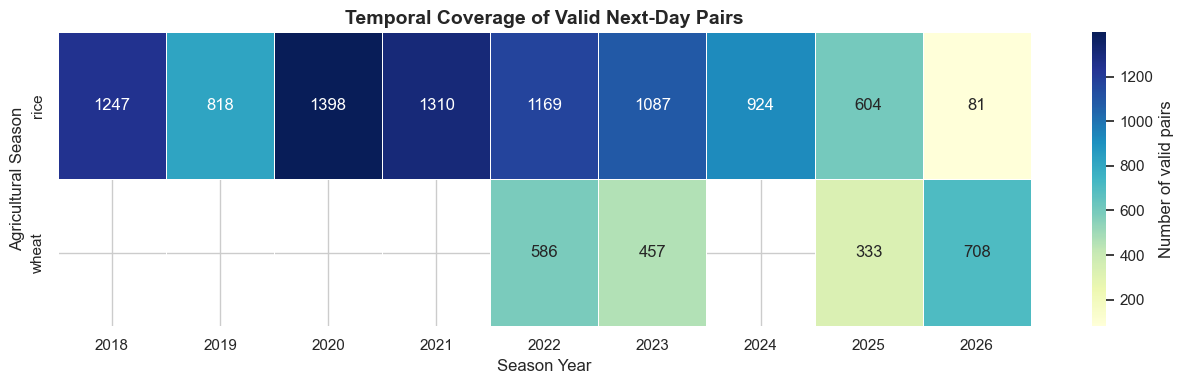

In [14]:

import seaborn as sns
import matplotlib.pyplot as plt

# Prepare year-season table for visualization

pair_heatmap_data = year_season_pairs.pivot(
    index="season",
    columns="season_year",
    values="valid_pairs"
)

# Plot heatmap

plt.figure(figsize=(13, 4))

sns.heatmap(
    pair_heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Number of valid pairs"}
)

plt.title(
    "Temporal Coverage of Valid Next-Day Pairs",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Season Year")
plt.ylabel("Agricultural Season")

plt.tight_layout()
plt.show()


In [15]:
display(pair_heatmap_data)

season_year,2018,2019,2020,2021,2022,2023,2024,2025,2026
season,,,,,,,,,
rice,1247.0,818.0,1398.0,1310.0,1169.0,1087.0,924.0,604.0,81.0
wheat,NaN,NaN,NaN,NaN,586.0,457.0,NaN,333.0,708.0



### 📊 Step 19: Distribution of Next-Day Burning Counts

We examine the distribution of `fires_day` among valid consecutive-day pairs.

This helps us understand whether the prediction target is balanced or highly skewed, and whether extreme observations may strongly influence regression model performance.

We will investigate the distribution before deciding whether any transformation is appropriate. We will not remove high values merely because they are extreme.


NEXT-DAY TARGET STATISTICS:


count    10722.000000
mean        39.131412
std         80.890848
min          1.000000
25%          3.000000
50%         10.000000
75%         35.000000
90%        104.000000
95%        188.000000
99%        412.000000
max        893.000000
Name: fires_day, dtype: float64

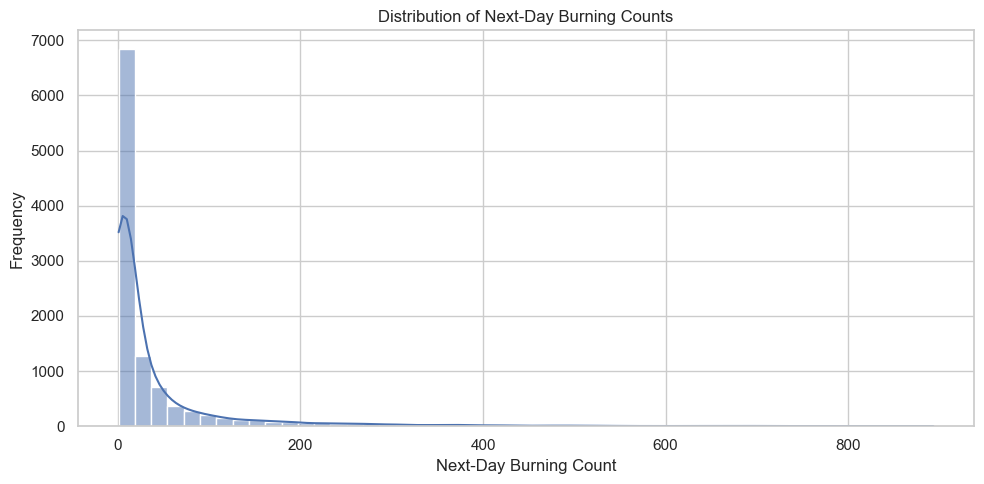

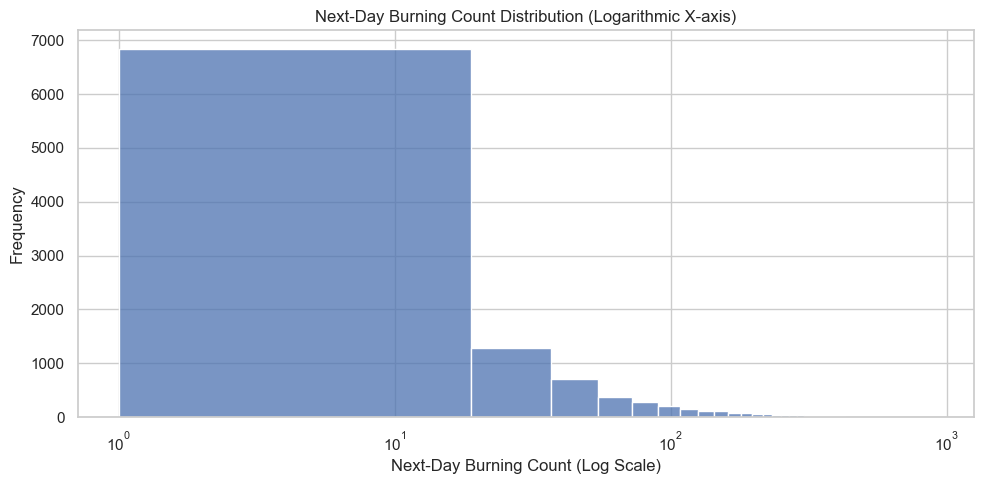

In [16]:

# 1. Descriptive statistics of next-day target

print("NEXT-DAY TARGET STATISTICS:")
display(valid_pairs["fires_day"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))


# 2. Plot target distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=valid_pairs,
    x="fires_day",
    bins=50,
    kde=True
)

plt.title("Distribution of Next-Day Burning Counts")
plt.xlabel("Next-Day Burning Count")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# 3. Examine the distribution using a logarithmic x-axis

plt.figure(figsize=(10, 5))

sns.histplot(
    data=valid_pairs,
    x="fires_day",
    bins=50
)

plt.xscale("log")

plt.title("Next-Day Burning Count Distribution (Logarithmic X-axis)")
plt.xlabel("Next-Day Burning Count (Log Scale)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()



### 🌾 Step 20: Season-Wise Target Distribution

We compare next-day burning counts between rice and wheat seasons.

This helps identify differences in target magnitude, variability and extreme observations across agricultural seasons.


In [17]:

# Compare target statistics by season

season_target_summary = (
    valid_pairs
    .groupby("season")["fires_day"]
    .agg(
        ["count", "mean", "median", "std", "min", "max"]
    )
)

season_target_summary["p90"] = (
    valid_pairs.groupby("season")["fires_day"].quantile(0.90)
)

season_target_summary["p95"] = (
    valid_pairs.groupby("season")["fires_day"].quantile(0.95)
)

season_target_summary["p99"] = (
    valid_pairs.groupby("season")["fires_day"].quantile(0.99)
)

print("SEASON-WISE TARGET DISTRIBUTION:")
display(season_target_summary)


SEASON-WISE TARGET DISTRIBUTION:


,count,mean,median,std,min,max,p90,p95,p99
season,,,,,,,,,
rice,8638,43.713938,10.0,88.313796,1.0,893.0,124.0,217.15,445.63
wheat,2084,20.137236,9.0,29.841900,1.0,263.0,53.0,81.85,144.34



### 📍 Step 21: State-Wise Target Distribution

We compare daily burning counts between Punjab and Haryana.

This analysis helps identify geographical differences in target magnitude, variability and extreme observations.


In [18]:

state_target_summary = (
    valid_pairs
    .groupby("state")["fires_day"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
)

state_target_summary["p90"] = (
    valid_pairs.groupby("state")["fires_day"].quantile(0.90)
)

state_target_summary["p95"] = (
    valid_pairs.groupby("state")["fires_day"].quantile(0.95)
)

state_target_summary["p99"] = (
    valid_pairs.groupby("state")["fires_day"].quantile(0.99)
)

print("STATE-WISE TARGET DISTRIBUTION:")
display(state_target_summary)


STATE-WISE TARGET DISTRIBUTION:


,count,mean,median,std,minimum,maximum,p90,p95,p99
state,,,,,,,,,
Haryana,3496,11.175629,5.0,16.263796,1.0,198.0,29.0,43.00,77.0
Punjab,7226,52.656657,15.0,94.975856,1.0,893.0,151.0,241.75,478.0



### ✅ Step 22: Finalize and Export Cleaned CREAMS Data

We preserve the cleaned full CREAMS dataset, including records with missing daily counts.

We also create a separate Punjab-Haryana modelling dataset containing available daily target observations. Records with suspicious district labels are excluded from this modelling copy but remain preserved in the full cleaned dataset.

Missing daily counts are not replaced with zero.


In [19]:

# 1. Create output directory

CLEANED_DIR = os.path.join(PROCESSED_DIR, "cleaned")

os.makedirs(CLEANED_DIR, exist_ok=True)


# 2. Preserve the complete cleaned CREAMS dataset

creams_daily_clean.to_csv(
    os.path.join(CLEANED_DIR, "creams_daily_clean.csv"),
    index=False
)


# 3. Create Punjab-Haryana target dataset

creams_ph_target = creams_daily_clean[
    (creams_daily_clean["state"].isin(["Punjab", "Haryana"])) &
    (creams_daily_clean["fires_day"].notna()) &
    (~creams_daily_clean["district"].isin(["Punjab", "Kharar"]))
].copy()


# 4. Sort records

creams_ph_target = creams_ph_target.sort_values(
    ["state", "district", "season_year", "season", "date"]
).reset_index(drop=True)


# 5. Export modelling-ready target dataset

creams_ph_target.to_csv(
    os.path.join(CLEANED_DIR, "creams_ph_target.csv"),
    index=False
)


# 6. Verify exported datasets

print("CREAMS CLEANING EXPORT COMPLETE")

print("\nFull cleaned dataset:", creams_daily_clean.shape)

print("Punjab-Haryana target dataset:", creams_ph_target.shape)

print("\nMissing target values in full dataset:",
      creams_daily_clean["fires_day"].isna().sum())

print("\nMissing target values in modelling dataset:",
      creams_ph_target["fires_day"].isna().sum())

print("\nSuspicious labels in modelling dataset:",
      creams_ph_target["district"].isin(["Punjab", "Kharar"]).sum())

print("\nExported files:")
print(os.listdir(CLEANED_DIR))


CREAMS CLEANING EXPORT COMPLETE

Full cleaned dataset: (198423, 13)
Punjab-Haryana target dataset: (14392, 13)

Missing target values in full dataset: 155894

Missing target values in modelling dataset: 0

Suspicious labels in modelling dataset: 0

Exported files:
['creams_daily_clean.csv', 'creams_ph_target.csv']



### 📄 Step 23: Cleaning CREAMS Bulletin Metadata

The bulletin catalogue contains metadata about the source documents used to compile CREAMS observations.

We will standardize date and categorical columns, preserve duplicate-document references, and retain records with incomplete metadata where appropriate.


In [21]:

# 1. Create a working copy
creams_bulletins=pd.read_csv("../Data/Raw_data/CREAMS/bulletins.csv")

creams_bulletins_clean = creams_bulletins.copy()


# 2. Convert date column

creams_bulletins_clean["date"] = pd.to_datetime(
    creams_bulletins_clean["date"],
    errors="coerce"
)


# 3. Standardize text columns

text_columns = [
    "season",
    "kind",
    "file",
    "url",
    "duplicate_of"
]

for col in text_columns:
    creams_bulletins_clean[col] = (
        creams_bulletins_clean[col]
        .astype("string")
        .str.strip()
    )


# 4. Convert numeric metadata

creams_bulletins_clean["bulletin_no"] = pd.to_numeric(
    creams_bulletins_clean["bulletin_no"],
    errors="coerce"
)

creams_bulletins_clean["pages"] = pd.to_numeric(
    creams_bulletins_clean["pages"],
    errors="coerce"
).astype("Int64")


# 5. Inspect cleaned result

print("CLEANED BULLETINS SHAPE:", creams_bulletins_clean.shape)

print("\nDATA TYPES:")
print(creams_bulletins_clean.dtypes)

print("\nMISSING VALUES:")
display(creams_bulletins_clean.isna().sum())


CLEANED BULLETINS SHAPE: (862, 10)

DATA TYPES:
date            datetime64[ns]
season          string[python]
kind            string[python]
bulletin_no            float64
file            string[python]
url             string[python]
pages                    Int64
primary                float64
duplicate_of    string[python]
error                  float64
dtype: object

MISSING VALUES:


date              6
season            6
kind              0
bulletin_no       6
file              0
url               0
pages             0
primary           6
duplicate_of    805
error           862
dtype: int64


### 🧾 Step 24: Preparing CREAMS Validation Metadata

The validation.json file contains quality-control findings from the original CREAMS extraction process.

We will preserve all validation categories and their findings without deleting, modifying or resolving reported inconsistencies.


In [22]:

import json
import os

validation_path = os.path.join(RAW_DIR, "creams", "validation.json")

with open(validation_path, "r", encoding="utf-8") as file:
    creams_validation = json.load(file)

print("Validation JSON loaded successfully!")
print("Data type:", type(creams_validation))
print("Keys:", creams_validation.keys())


Validation JSON loaded successfully!
Data type: <class 'dict'>
Keys: dict_keys(['failed', 'events_vs_highlights', 'table_total_vs_highlights', 'table_sum_vs_total', 'district_sum_vs_total', 'non_monotonic_cumulative', 'cum_delta_vs_day', 'no_highlights', 'date_mismatch', 'duplicates', 'event_list_other_date', 'summary', 'event_districts_unmatched'])


In [23]:

# 1. Create a separate working copy

import copy


creams_validation_clean = copy.deepcopy(creams_validation)


# 2. Inspect top-level structure

print("VALIDATION DATA TYPE:", type(creams_validation_clean))

print("\nVALIDATION KEYS:")

for key, value in creams_validation_clean.items():
    if isinstance(value, list):
        print(f"{key}: {len(value)} records")
    elif isinstance(value, dict):
        print(f"{key}: dictionary with {len(value)} keys")
    else:
        print(f"{key}: {type(value).__name__}")


# 3. Verify important validation summary

print("\nVALIDATION SUMMARY:")

display(pd.Series(creams_validation_clean["summary"]))


# 4. Verify that findings have been preserved

print("\nORIGINAL AND CLEANED VALIDATION MATCH:",
      creams_validation_clean == creams_validation)


VALIDATION DATA TYPE: <class 'dict'>

VALIDATION KEYS:
failed: 0 records
events_vs_highlights: 20 records
table_total_vs_highlights: 7 records
table_sum_vs_total: 309 records
district_sum_vs_total: 31 records
non_monotonic_cumulative: 1 records
cum_delta_vs_day: 34 records
no_highlights: 14 records
date_mismatch: 4 records
duplicates: 57 records
event_list_other_date: 6 records
summary: dictionary with 14 keys
event_districts_unmatched: 2 records

VALIDATION SUMMARY:


failed                             0
events_vs_highlights              20
table_total_vs_highlights          7
table_sum_vs_total               309
district_sum_vs_total             31
non_monotonic_cumulative           1
cum_delta_vs_day                  34
no_highlights                     14
date_mismatch                      4
duplicates                        57
event_list_other_date              6
primary_bulletins                799
pdfs                             862
event_rows_district_unmatched      7
dtype: int64


ORIGINAL AND CLEANED VALIDATION MATCH: True


In [24]:

CLEANED_DIR = os.path.join(PROCESSED_DIR, "cleaned")
os.makedirs(CLEANED_DIR, exist_ok=True)

creams_bulletins_clean.to_csv(
    os.path.join(CLEANED_DIR, "creams_bulletins_clean.csv"),
    index=False
)

print("Cleaned bulletins saved successfully!")


Cleaned bulletins saved successfully!


In [25]:

validation_output_path = os.path.join(
    CLEANED_DIR, "creams_validation_clean.json"
)

with open(validation_output_path, "w", encoding="utf-8") as file:
    json.dump(creams_validation, file, indent=4, ensure_ascii=False)

print("Validation JSON saved successfully!")


Validation JSON saved successfully!



### 🧹 Step 25: Cleaning CREAMS State-Level Daily Data

Load the original state_daily.csv file, create a separate working copy, standardize column data types, and preserve missing values.


In [26]:

# 1. Load raw dataset

creams_state_daily_raw = pd.read_csv(
    os.path.join(RAW_DIR, "creams", "state_daily.csv")
)

# 2. Create working copy

creams_state_daily_clean = creams_state_daily_raw.copy()

# 3. Convert date columns

date_columns = ["date", "cum_period_start"]

for col in date_columns:
    if col in creams_state_daily_clean.columns:
        creams_state_daily_clean[col] = pd.to_datetime(
            creams_state_daily_clean[col],
            errors="coerce"
        )

# 4. Standardize text columns

text_columns = [
    "season", "state", "day_source",
    "cum_source", "cum_check",
    "bulletin_file", "cum_bulletin_file"
]

for col in text_columns:
    if col in creams_state_daily_clean.columns:
        creams_state_daily_clean[col] = (
            creams_state_daily_clean[col]
            .astype("string")
            .str.strip()
        )

# 5. Convert numeric columns

numeric_columns = [
    "season_year", "fires_day_as_published",
    "fires_cumulative"
]

for col in numeric_columns:
    if col in creams_state_daily_clean.columns:
        creams_state_daily_clean[col] = pd.to_numeric(
            creams_state_daily_clean[col],
            errors="coerce"
        )

# 6. Inspect result

print("CLEANED SHAPE:", creams_state_daily_clean.shape)
print("\nDATA TYPES:")
print(creams_state_daily_clean.dtypes)

print("\nMISSING VALUES:")
display(creams_state_daily_clean.isna().sum())


CLEANED SHAPE: (5588, 12)

DATA TYPES:
date                      datetime64[ns]
season                    string[python]
season_year                        int64
state                     string[python]
fires_day                          int64
fires_cumulative                 float64
cum_start                         object
day_source                string[python]
cum_source                string[python]
fires_day_as_published           float64
bulletin_file             string[python]
cum_bulletin_file         string[python]
dtype: object

MISSING VALUES:


date                      3680
season                       0
season_year                  0
state                        0
fires_day                    0
fires_cumulative            11
cum_start                   11
day_source                   0
cum_source                  11
fires_day_as_published    1637
bulletin_file                0
cum_bulletin_file           11
dtype: int64


### 🔍 Step 26: Investigating Missing State-Level Dates

Check the original date values for records that became missing during datetime conversion. Preserve all records and investigate before making corrections.


In [27]:

# Compare original and cleaned date values

missing_date_mask = creams_state_daily_clean["date"].isna()

print("Missing dates after conversion:",
      missing_date_mask.sum())

print("\nOriginal date examples:")
display(
    creams_state_daily_raw.loc[
        missing_date_mask, "date"
    ].head(20)
)

print("\nOriginal date data type:",
      creams_state_daily_raw["date"].dtype)

print("\nUnique original date examples:")
display(
    creams_state_daily_raw["date"]
    .value_counts(dropna=False)
    .head(15)
)


Missing dates after conversion: 3680

Original date examples:


36    13-10-2016
37    13-10-2016
38    13-10-2016
39    14-10-2016
40    14-10-2016
41    14-10-2016
42    15-10-2016
43    15-10-2016
44    15-10-2016
45    16-10-2016
46    16-10-2016
47    16-10-2016
48    17-10-2016
49    17-10-2016
50    17-10-2016
51    18-10-2016
52    18-10-2016
53    18-10-2016
54    19-10-2016
55    19-10-2016
Name: date, dtype: object


Original date data type: object

Unique original date examples:


date
06-10-2023    7
27-10-2026    7
26-10-2026    7
25-10-2026    7
24-10-2026    7
23-10-2026    7
22-10-2026    7
21-10-2026    7
20-10-2026    7
20-09-2023    7
21-09-2023    7
22-09-2023    7
23-09-2023    7
24-09-2023    7
25-09-2023    7
Name: count, dtype: int64


### 🛠️ Step 27: Correcting Date Format

The original dates use DD-MM-YYYY format. Convert both date columns explicitly using dayfirst=True to prevent incorrect date interpretation.


In [28]:

# Correct date conversion

creams_state_daily_clean["date"] = pd.to_datetime(
    creams_state_daily_raw["date"],
    errors="coerce",
    dayfirst=True
)

creams_state_daily_clean["cum_start"] = pd.to_datetime(
    creams_state_daily_raw["cum_start"],
    errors="coerce",
    dayfirst=True
)

# Verify

print("Missing dates:", creams_state_daily_clean["date"].isna().sum())
print("Missing cumulative start dates:",
      creams_state_daily_clean["cum_start"].isna().sum())

print("\nDate range:")
print(creams_state_daily_clean["date"].min(),
      "to",
      creams_state_daily_clean["date"].max())

print("\nUpdated data types:")
print(creams_state_daily_clean[["date", "cum_start"]].dtypes)


Missing dates: 0
Missing cumulative start dates: 11

Date range:
2016-10-01 00:00:00 to 2026-10-27 00:00:00

Updated data types:
date         datetime64[ns]
cum_start    datetime64[ns]
dtype: object


In [29]:

creams_state_daily_clean.to_csv(
    os.path.join(CLEANED_DIR, "creams_state_daily_clean.csv"),
    index=False
)

print("Cleaned state daily dataset saved successfully!")
print("Shape:", creams_state_daily_clean.shape)


Cleaned state daily dataset saved successfully!
Shape: (5588, 12)



### 🧹 Step 29: Cleaning CREAMS Year Comparison Data

Load year_compare.csv, create a working copy, convert date columns, standardize text columns and convert numeric columns without removing original records.


In [30]:

# 1. Load raw dataset

creams_year_compare_raw = pd.read_csv(
    os.path.join(RAW_DIR, "creams", "year_compare.csv")
)

# 2. Create working copy

creams_year_compare_clean = creams_year_compare_raw.copy()

# 3. Convert date columns

date_columns = ["as_of_date", "bulletin_date"]

for col in date_columns:
    if col in creams_year_compare_clean.columns:
        creams_year_compare_clean[col] = pd.to_datetime(
            creams_year_compare_clean[col],
            errors="coerce",
            dayfirst=True
        )

# 4. Standardize text columns

text_columns = [
    "season", "state", "note",
    "bulletin_file"
]

for col in text_columns:
    if col in creams_year_compare_clean.columns:
        creams_year_compare_clean[col] = (
            creams_year_compare_clean[col]
            .astype("string")
            .str.strip()
        )

# 5. Convert remaining numeric columns

for col in creams_year_compare_clean.columns:
    if col not in date_columns + text_columns:
        creams_year_compare_clean[col] = pd.to_numeric(
            creams_year_compare_clean[col],
            errors="coerce"
        )

# 6. Inspect cleaned dataset

print("CLEANED SHAPE:", creams_year_compare_clean.shape)

print("\nDATA TYPES:")
print(creams_year_compare_clean.dtypes)

print("\nMISSING VALUES:")
display(creams_year_compare_clean.isna().sum())


CLEANED SHAPE: (5577, 10)

DATA TYPES:
season              string[python]
state               string[python]
as_of_date          datetime64[ns]
year                         int64
cumulative_fires             int64
period_start               float64
source                     float64
bulletin_date       datetime64[ns]
bulletin_file       string[python]
note                string[python]
dtype: object

MISSING VALUES:


C:\Users\kenpa\AppData\Local\Temp\ipykernel_428\1706812202.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  creams_year_compare_clean[col] = pd.to_datetime(
C:\Users\kenpa\AppData\Local\Temp\ipykernel_428\1706812202.py:17: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  creams_year_compare_clean[col] = pd.to_datetime(


season                 0
state                  0
as_of_date          5577
year                   0
cumulative_fires       0
period_start        5577
source              5577
bulletin_date          0
bulletin_file          0
note                5574
dtype: int64


### 🔍 Step 30: Investigating Year Comparison Conversion

Inspect the original values and data types of as_of_date, period_start and source to identify incorrect conversions before finalizing the cleaned dataset.


In [31]:

columns_to_check = ["as_of_date", "period_start", "source"]

for col in columns_to_check:
    print(f"\n--- {col} ---")
    print("Original dtype:", creams_year_compare_raw[col].dtype)
    display(creams_year_compare_raw[col].dropna().head(10))



--- as_of_date ---
Original dtype: object


0    09-15
1    09-15
2    09-15
3    09-15
4    09-15
5    09-15
6    09-15
7    09-16
8    09-16
9    09-16
Name: as_of_date, dtype: object


--- period_start ---
Original dtype: object


0    09-15
1    09-15
2    09-15
3    09-15
4    09-15
5    09-15
6    09-15
7    09-15
8    09-15
9    09-15
Name: period_start, dtype: object


--- source ---
Original dtype: object


0    datewise_table_total
1    datewise_table_total
2    datewise_table_total
3    datewise_table_total
4    datewise_table_total
5    datewise_table_total
6    datewise_table_total
7    datewise_table_total
8    datewise_table_total
9    datewise_table_total
Name: source, dtype: object


### 🛠️ Step 31: Correcting Year Comparison Column Types

Preserve as_of_date and period_start as month-day strings because they do not contain a year. Convert source back to a categorical text column.


In [32]:

# Restore month-day values from original dataset

for col in ["as_of_date", "period_start"]:
    creams_year_compare_clean[col] = (
        creams_year_compare_raw[col]
        .astype("string")
        .str.strip()
    )

# Restore source as text

creams_year_compare_clean["source"] = (
    creams_year_compare_raw["source"]
    .astype("string")
    .str.strip()
)

# Verify

print("UPDATED DATA TYPES:")
print(creams_year_compare_clean.dtypes)

print("\nMISSING VALUES:")
display(creams_year_compare_clean.isna().sum())

print("\nAS_OF_DATE EXAMPLES:")
display(creams_year_compare_clean["as_of_date"].head())

print("\nPERIOD_START EXAMPLES:")
display(creams_year_compare_clean["period_start"].head())

print("\nSOURCE VALUES:")
print(creams_year_compare_clean["source"].value_counts(dropna=False))


UPDATED DATA TYPES:
season              string[python]
state               string[python]
as_of_date          string[python]
year                         int64
cumulative_fires             int64
period_start        string[python]
source              string[python]
bulletin_date       datetime64[ns]
bulletin_file       string[python]
note                string[python]
dtype: object

MISSING VALUES:


season                 0
state                  0
as_of_date             0
year                   0
cumulative_fires       0
period_start           0
source                 0
bulletin_date          0
bulletin_file          0
note                5574
dtype: int64


AS_OF_DATE EXAMPLES:


0    09-15
1    09-15
2    09-15
3    09-15
4    09-15
Name: as_of_date, dtype: string


PERIOD_START EXAMPLES:


0    09-15
1    09-15
2    09-15
3    09-15
4    09-15
Name: period_start, dtype: string


SOURCE VALUES:
source
datewise_table_total    5577
Name: count, dtype: Int64


In [33]:

creams_year_compare_clean.to_csv(
    os.path.join(CLEANED_DIR, "creams_year_compare_clean.csv"),
    index=False
)

print("Cleaned year comparison saved successfully!")
print("Shape:", creams_year_compare_clean.shape)


Cleaned year comparison saved successfully!
Shape: (5577, 10)



### 🛰️ Step 33: Cleaning FIRMS District-Level Daily Data

Load the compressed district_daily_paddy.csv.gz dataset, create a working copy, standardize text and numeric columns, and preserve all observations.


In [34]:

# 1. Load raw dataset

fires_daily_raw = pd.read_csv(
    os.path.join(RAW_DIR, "FIRMS", "district_daily_paddy.csv.gz")
)

# 2. Create working copy

fires_daily_clean = fires_daily_raw.copy()

# 3. Standardize text columns

text_columns = [
    "season", "district", "state",
    "country", "sensor"
]

for col in text_columns:
    if col in fires_daily_clean.columns:
        fires_daily_clean[col] = (
            fires_daily_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert numeric columns

numeric_columns = [
    "year", "detections"
]

for col in numeric_columns:
    if col in fires_daily_clean.columns:
        fires_daily_clean[col] = pd.to_numeric(
            fires_daily_clean[col],
            errors="coerce"
        )

# 5. Inspect

print("CLEANED SHAPE:", fires_daily_clean.shape)

print("\nDATA TYPES:")
print(fires_daily_clean.dtypes)

print("\nMISSING VALUES:")
display(fires_daily_clean.isna().sum())


CLEANED SHAPE: (427728, 8)

DATA TYPES:
year                     int64
sensor_group            object
date                    object
district_id              int64
district        string[python]
state           string[python]
country         string[python]
detections               int64
dtype: object

MISSING VALUES:


year            0
sensor_group    0
date            0
district_id     0
district        0
state           0
country         0
detections      0
dtype: int64


### 📅 Step 34: Standardizing FIRMS Dates and Sensor Groups

Convert the observation date into datetime format and standardize the sensor_group text column. Preserve all records.


In [35]:

# Convert date column

fires_daily_clean["date"] = pd.to_datetime(
    fires_daily_raw["date"],
    errors="coerce"
)

# Standardize sensor group

fires_daily_clean["sensor_group"] = (
    fires_daily_raw["sensor_group"]
    .astype("string")
    .str.strip()
)

# Verify

print("MISSING DATES:",
      fires_daily_clean["date"].isna().sum())

print("\nDATE RANGE:")
print(
    fires_daily_clean["date"].min(),
    "to",
    fires_daily_clean["date"].max()
)

print("\nSENSOR GROUPS:")
print(fires_daily_clean["sensor_group"].value_counts())

print("\nUPDATED DATA TYPES:")
print(fires_daily_clean.dtypes)


MISSING DATES: 0

DATE RANGE:
2003-09-15 00:00:00 to 2026-10-28 00:00:00

SENSOR GROUPS:
sensor_group
viirs    200690
snpp     153309
modis     73729
Name: count, dtype: Int64

UPDATED DATA TYPES:
year                     int64
sensor_group    string[python]
date            datetime64[ns]
district_id              int64
district        string[python]
state           string[python]
country         string[python]
detections               int64
dtype: object


In [36]:

fires_clean_dir = os.path.join(CLEANED_DIR, "fires")
os.makedirs(fires_clean_dir, exist_ok=True)

fires_daily_clean.to_csv(
    os.path.join(fires_clean_dir, "fires_district_daily_clean.csv.gz"),
    index=False,
    compression="gzip"
)

print("FIRMS daily dataset saved successfully!")
print("Shape:", fires_daily_clean.shape)


FIRMS daily dataset saved successfully!
Shape: (427728, 8)



### 🛰️ Step 36: Cleaning FIRMS District Seasonal Data

Load district_season.csv, create a separate working copy, standardize text columns and convert numeric columns while preserving all records and missing values.


In [38]:

# 1. Load raw dataset

fires_season_raw = pd.read_csv(
    os.path.join(RAW_DIR, "FIRMS", "district_season.csv")
)

# 2. Create working copy

fires_season_clean = fires_season_raw.copy()

# 3. Standardize text columns

text_columns = [
    "season", "district", "state",
    "country", "sensor"
]

for col in text_columns:
    if col in fires_season_clean.columns:
        fires_season_clean[col] = (
            fires_season_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert numeric columns

numeric_columns = [
    "year", "district_id", "detections"
]

for col in numeric_columns:
    if col in fires_season_clean.columns:
        fires_season_clean[col] = pd.to_numeric(
            fires_season_clean[col],
            errors="coerce"
        )

# 5. Inspect cleaned dataset

print("CLEANED SHAPE:", fires_season_clean.shape)

print("\nDATA TYPES:")
print(fires_season_clean.dtypes)

print("\nMISSING VALUES:")
display(fires_season_clean.isna().sum())


CLEANED SHAPE: (84875, 8)

DATA TYPES:
year                    int64
season         string[python]
district_id             int64
district       string[python]
state          string[python]
country        string[python]
sensor         string[python]
detections              int64
dtype: object

MISSING VALUES:


year           0
season         0
district_id    0
district       0
state          0
country        0
sensor         0
detections     0
dtype: int64

In [39]:

fires_season_clean.to_csv(
    os.path.join(fires_clean_dir, "fires_district_season_clean.csv"),
    index=False
)

print("FIRMS seasonal dataset saved successfully!")
print("Shape:", fires_season_clean.shape)


FIRMS seasonal dataset saved successfully!
Shape: (84875, 8)



### 🛰️ Step 38: Cleaning FIRMS Seasonal Totals

Load season_totals.csv, create a working copy, standardize text columns and convert numeric columns. Preserve missing values and all original records.


In [44]:

# 1. Load raw dataset
fires_totals_raw = pd.read_csv(
    os.path.join(RAW_DIR, "FIRMS", "season_totals.csv")
)

# 2. Create working copy

fires_totals_clean = fires_totals_raw.copy()

# 3. Standardize text columns

text_columns = [
    "season", "state", "country", "sensor"
]

for col in text_columns:
    if col in fires_totals_clean.columns:
        fires_totals_clean[col] = (
            fires_totals_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert numeric columns

numeric_columns = [
    "year", "detections", "frp_mw_sum"
]

for col in numeric_columns:
    if col in fires_totals_clean.columns:
        fires_totals_clean[col] = pd.to_numeric(
            fires_totals_clean[col],
            errors="coerce"
        )

# 5. Inspect cleaned dataset

print("CLEANED SHAPE:", fires_totals_clean.shape)

print("\nDATA TYPES:")
print(fires_totals_clean.dtypes)

print("\nMISSING VALUES:")
display(fires_totals_clean.isna().sum())


CLEANED SHAPE: (5654, 7)

DATA TYPES:
year                   int64
season        string[python]
state         string[python]
country       string[python]
sensor        string[python]
detections             int64
frp_mw_sum             int64
dtype: object

MISSING VALUES:


year            0
season          0
state           0
country       136
sensor          0
detections      0
frp_mw_sum      0
dtype: int64


### 💾 Step 39: Export Cleaned FIRMS Seasonal Totals

Save the cleaned seasonal totals dataset while preserving the 136 missing country values and all original observations.


In [45]:



fires_totals_clean.to_csv(
    os.path.join(fires_clean_dir, "fires_season_totals_clean.csv"),
    index=False
)

print("FIRMS season totals saved successfully!")
print("Shape:", fires_totals_clean.shape)


FIRMS season totals saved successfully!
Shape: (5654, 7)



### 🌾 Step 40: Cleaning District-Level Rice Area Data

Load rice_area_district.csv, create a working copy, standardize text columns and convert numeric columns. Preserve all original records and missing values.


In [46]:

# 1. Load raw dataset

paddy_district_raw = pd.read_csv(
    os.path.join(RAW_DIR, "PADDY", "rice_area_district.csv")
)

# 2. Create working copy

paddy_district_clean = paddy_district_raw.copy()

# 3. Standardize text columns

text_columns = [
    "state", "district"
]

for col in text_columns:
    if col in paddy_district_clean.columns:
        paddy_district_clean[col] = (
            paddy_district_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert numeric columns

for col in paddy_district_clean.columns:
    if col not in text_columns:
        paddy_district_clean[col] = pd.to_numeric(
            paddy_district_clean[col],
            errors="coerce"
        )

# 5. Inspect

print("CLEANED SHAPE:", paddy_district_clean.shape)

print("\nDATA TYPES:")
print(paddy_district_clean.dtypes)

print("\nMISSING VALUES:")
display(paddy_district_clean.isna().sum())


CLEANED SHAPE: (6674, 12)

DATA TYPES:
state               string[python]
district            string[python]
lgd_code                     int64
district_id                  int64
district_id_name           float64
match_method               float64
year                         int64
agri_year                  float64
kharif_area_ha             float64
kharif_prod_t              float64
total_area_ha                int64
total_prod_t               float64
dtype: object

MISSING VALUES:


state                  0
district               0
lgd_code               0
district_id            0
district_id_name    6674
match_method        6674
year                   0
agri_year           6674
kharif_area_ha         8
kharif_prod_t         16
total_area_ha          0
total_prod_t           8
dtype: int64


### 💾 Step 41: Finalizing District-Level Paddy Data

Verify missing values in agricultural measurements and export the cleaned dataset without deleting records or imputing missing values.


In [47]:

# 1. Complete missing-value inspection

print("MISSING VALUES:")
display(paddy_district_clean.isna().sum())

# 2. Export cleaned dataset

paddy_clean_dir = os.path.join(CLEANED_DIR, "paddy")
os.makedirs(paddy_clean_dir, exist_ok=True)

paddy_district_clean.to_csv(
    os.path.join(paddy_clean_dir, "paddy_rice_area_district_clean.csv"),
    index=False
)

print("\nDistrict-level paddy data saved!")
print("Shape:", paddy_district_clean.shape)


MISSING VALUES:


state                  0
district               0
lgd_code               0
district_id            0
district_id_name    6674
match_method        6674
year                   0
agri_year           6674
kharif_area_ha         8
kharif_prod_t         16
total_area_ha          0
total_prod_t           8
dtype: int64


District-level paddy data saved!
Shape: (6674, 12)


In [48]:

# 1. Load raw dataset

paddy_state_raw = pd.read_csv(
    os.path.join(RAW_DIR, "paddy", "rice_area_state.csv")
)

# 2. Create working copy

paddy_state_clean = paddy_state_raw.copy()

# 3. Standardize text columns

text_columns = ["state"]

for col in text_columns:
    if col in paddy_state_clean.columns:
        paddy_state_clean[col] = (
            paddy_state_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert remaining columns to numeric

for col in paddy_state_clean.columns:
    if col not in text_columns:
        paddy_state_clean[col] = pd.to_numeric(
            paddy_state_clean[col],
            errors="coerce"
        )

# 5. Inspect

print("CLEANED SHAPE:", paddy_state_clean.shape)

print("\nDATA TYPES:")
print(paddy_state_clean.dtypes)

print("\nMISSING VALUES:")
display(paddy_state_clean.isna().sum())


CLEANED SHAPE: (508, 10)

DATA TYPES:
state                          string[python]
year                                    int64
agri_year                             float64
kharif_area_ha                        float64
kharif_prod_t                         float64
total_area_ha                         float64
total_prod_t                          float64
district_sum_kharif_area_ha           float64
district_sum_kharif_prod_t            float64
estimate_type                         float64
dtype: object

MISSING VALUES:


state                            0
year                             0
agri_year                      508
kharif_area_ha                   3
kharif_prod_t                    3
total_area_ha                    3
total_prod_t                     3
district_sum_kharif_area_ha    287
district_sum_kharif_prod_t     287
estimate_type                  508
dtype: int64

In [49]:

paddy_state_clean.to_csv(
    os.path.join(paddy_clean_dir, "paddy_rice_area_state_clean.csv"),
    index=False
)

print("State-level paddy data saved successfully!")
print("Shape:", paddy_state_clean.shape)


State-level paddy data saved successfully!
Shape: (508, 10)



### 🗺️ Step 44: Preparing District Geographic Boundaries

Load districts.geojson using GeoPandas and inspect its geometry, coordinate reference system, columns and missing values.


In [50]:

# Import GeoPandas

import geopandas as gpd

# Load district boundaries

districts_raw = gpd.read_file(
    os.path.join(RAW_DIR, "boundaries", "districts.geojson")
)

# Create working copy

districts_clean = districts_raw.copy()

# Inspect

print("SHAPE:", districts_clean.shape)

print("\nCOLUMNS:")
print(districts_clean.columns.tolist())

print("\nDATA TYPES:")
print(districts_clean.dtypes)

print("\nCRS:")
print(districts_clean.crs)

print("\nGEOMETRY TYPES:")
print(districts_clean.geom_type.value_counts())

print("\nMISSING VALUES:")
display(districts_clean.isna().sum())

print("\nINVALID GEOMETRIES:",
      (~districts_clean.geometry.is_valid).sum())

print("\nEMPTY GEOMETRIES:",
      districts_clean.geometry.is_empty.sum())


SHAPE: (857, 6)

COLUMNS:
['id', 'name', 'state', 'country', 'area_km2', 'geometry']

DATA TYPES:
id             int32
name          object
state         object
country       object
area_km2     float64
geometry    geometry
dtype: object

CRS:
EPSG:4326

GEOMETRY TYPES:
Polygon         814
MultiPolygon     43
Name: count, dtype: int64

MISSING VALUES:


id          0
name        0
state       0
country     0
area_km2    0
geometry    0
dtype: int64


INVALID GEOMETRIES: 1

EMPTY GEOMETRIES: 0



### 🔍 Step 45: Investigating Invalid District Geometry

Identify the district with invalid geometry and determine the reason for its geometric invalidity before deciding whether repair is necessary.


In [51]:

from shapely.validation import explain_validity

# Find invalid geometries

invalid_mask = ~districts_clean.geometry.is_valid

invalid_districts = districts_clean.loc[invalid_mask].copy()

print("INVALID GEOMETRY COUNT:", len(invalid_districts))

# Display affected district details

display(
    invalid_districts[
        ["id", "name", "state", "country", "area_km2"]
    ]
)

# Explain geometry errors

for idx, row in invalid_districts.iterrows():
    print(f"\nDistrict: {row['name']}, {row['state']}")
    print("Reason:", explain_validity(row.geometry))


INVALID GEOMETRY COUNT: 1


,id,name,state,country,area_km2
591,591,Karbi Anglong West,Assam,India,3010.1



District: Karbi Anglong West, Assam
Reason: Too few points in geometry component[92.3004 26.0752]


V
### 💾 Step 46: Export District Geographic Boundaries

Preserve and export the original district GeoJSON structure, including all geographic features and the documented invalid geometry.

In [53]:

boundaries_clean_dir = os.path.join(CLEANED_DIR, "boundaries")
os.makedirs(boundaries_clean_dir, exist_ok=True)

districts_clean.to_file(
    os.path.join(boundaries_clean_dir, "districts_clean.geojson"),
    driver="GeoJSON"
)

print("District boundaries exported successfully!")
print("Features:", len(districts_clean))
print("Invalid geometries:", (~districts_clean.geometry.is_valid).sum())


District boundaries exported successfully!
Features: 857
Invalid geometries: 1



### 🗺️ Step 47: Preparing State Geographic Boundaries

Load states.geojson using GeoPandas and inspect its structure, coordinate reference system, missing values and geometry validity.


In [54]:

states_raw = gpd.read_file(
    os.path.join(RAW_DIR, "boundaries", "states.geojson")
)

states_clean = states_raw.copy()

print("SHAPE:", states_clean.shape)

print("\nCOLUMNS:")
print(states_clean.columns.tolist())

print("\nDATA TYPES:")
print(states_clean.dtypes)

print("\nCRS:")
print(states_clean.crs)

print("\nGEOMETRY TYPES:")
print(states_clean.geom_type.value_counts())

print("\nMISSING VALUES:")
display(states_clean.isna().sum())

print("\nINVALID GEOMETRIES:",
      (~states_clean.geometry.is_valid).sum())

print("\nEMPTY GEOMETRIES:",
      states_clean.geometry.is_empty.sum())


SHAPE: (43, 3)

COLUMNS:
['name', 'country', 'geometry']

DATA TYPES:
name          object
country       object
geometry    geometry
dtype: object

CRS:
EPSG:4326

GEOMETRY TYPES:
Polygon         33
MultiPolygon    10
Name: count, dtype: int64

MISSING VALUES:


name        0
country     0
geometry    0
dtype: int64


INVALID GEOMETRIES: 1

EMPTY GEOMETRIES: 0



### 🔍 Step 48: Investigating Invalid State Geometry

Identify the state with invalid geometry and inspect the reason for its geometric invalidity. Do not automatically repair or remove it.


In [55]:

from shapely.validation import explain_validity

invalid_mask = ~states_clean.geometry.is_valid

invalid_states = states_clean.loc[invalid_mask].copy()

print("INVALID GEOMETRY COUNT:", len(invalid_states))

display(
    invalid_states[["name", "country"]]
)

for idx, row in invalid_states.iterrows():
    print(f"\nState: {row['name']}")
    print("Reason:", explain_validity(row.geometry))


INVALID GEOMETRY COUNT: 1


,name,country
31,Andaman and Nicobar Islands,India



State: Andaman and Nicobar Islands
Reason: Self-intersection[93.0903 13.4119]


In [56]:

states_clean.to_file(
    os.path.join(boundaries_clean_dir, "states_clean.geojson"),
    driver="GeoJSON"
)

print("State boundaries exported successfully!")
print("Features:", len(states_clean))
print("Invalid geometries:", (~states_clean.geometry.is_valid).sum())


State boundaries exported successfully!
Features: 43
Invalid geometries: 1



### 🔥 Step 50: Cleaning District-Level Seasonal Burned Area Data

Load district_season.csv, create a separate working copy, standardize text columns and convert numeric columns. Preserve all original records and missing values.


In [58]:

# 1. Load raw dataset

burned_district_raw = pd.read_csv(
    os.path.join(RAW_DIR, "Burned_areas", "district_season.csv")
)

# 2. Create working copy

burned_district_clean = burned_district_raw.copy()

# 3. Standardize text columns

text_columns = [
    "season", "district", "state", "country"
]

for col in text_columns:
    if col in burned_district_clean.columns:
        burned_district_clean[col] = (
            burned_district_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert remaining columns to numeric

for col in burned_district_clean.columns:
    if col not in text_columns:
        burned_district_clean[col] = pd.to_numeric(
            burned_district_clean[col],
            errors="coerce"
        )

# 5. Inspect

print("CLEANED SHAPE:", burned_district_clean.shape)

print("\nDATA TYPES:")
print(burned_district_clean.dtypes)

print("\nMISSING VALUES:")
display(burned_district_clean.isna().sum())


CLEANED SHAPE: (1265, 6)

DATA TYPES:
season         string[python]
district_id             int64
district       string[python]
state          string[python]
burned_ha               int64
complete                 bool
dtype: object

MISSING VALUES:


season         0
district_id    0
district       0
state          0
burned_ha      0
complete       0
dtype: int64

In [59]:

burned_clean_dir = os.path.join(CLEANED_DIR, "burned_area")
os.makedirs(burned_clean_dir, exist_ok=True)

burned_district_clean.to_csv(
    os.path.join(burned_clean_dir, "burned_district_season_clean.csv"),
    index=False
)

print("District seasonal burned-area data saved!")
print("Shape:", burned_district_clean.shape)


District seasonal burned-area data saved!
Shape: (1265, 6)



### 🔥 Step 52: Cleaning State-Level Daily Burned Area

Load daily_by_state.csv, create a working copy, standardize text columns and convert date and numeric columns. Preserve missing values and original records.


In [61]:

# 1. Load raw dataset

burned_daily_raw = pd.read_csv(
    os.path.join(RAW_DIR, "Burned_areas", "daily_by_state.csv")
)

# 2. Create working copy

burned_daily_clean = burned_daily_raw.copy()

# 3. Standardize text columns

text_columns = ["state"]

for col in text_columns:
    if col in burned_daily_clean.columns:
        burned_daily_clean[col] = (
            burned_daily_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert date column if present

if "date" in burned_daily_clean.columns:
    burned_daily_clean["date"] = pd.to_datetime(
        burned_daily_clean["date"],
        errors="coerce"
    )

# 5. Convert remaining columns to numeric

for col in burned_daily_clean.columns:
    if col not in text_columns + ["date"]:
        burned_daily_clean[col] = pd.to_numeric(
            burned_daily_clean[col],
            errors="coerce"
        )

# 6. Inspect

print("CLEANED SHAPE:", burned_daily_clean.shape)

print("\nDATA TYPES:")
print(burned_daily_clean.dtypes)

print("\nMISSING VALUES:")
display(burned_daily_clean.isna().sum())


CLEANED SHAPE: (7544, 6)

DATA TYPES:
season                 int64
date          datetime64[ns]
season_day             int64
state         string[python]
burned_ha            float64
complete                bool
dtype: object

MISSING VALUES:


season        0
date          0
season_day    0
state         0
burned_ha     0
complete      0
dtype: int64


### 💾 Step 53: Export Cleaned Daily Burned Area

Save the standardized state-level daily burned-area dataset.


In [62]:

burned_daily_clean.to_csv(
    os.path.join(burned_clean_dir, "burned_daily_by_state_clean.csv"),
    index=False
)

print("Daily burned-area data saved successfully!")
print("Shape:", burned_daily_clean.shape)


Daily burned-area data saved successfully!
Shape: (7544, 6)



### 🔥 Step 54: Cleaning State-Level Seasonal Burned Area

Load state_season.csv, create a working copy, standardize text columns and convert numeric columns. Preserve all records and missing values.


In [64]:

# 1. Load raw dataset

burned_state_raw = pd.read_csv(
    os.path.join(RAW_DIR, "Burned_areas", "state_season.csv")
)

# 2. Create working copy

burned_state_clean = burned_state_raw.copy()

# 3. Standardize text columns

text_columns = ["state"]

for col in text_columns:
    if col in burned_state_clean.columns:
        burned_state_clean[col] = (
            burned_state_clean[col]
            .astype("string")
            .str.strip()
        )

# 4. Convert remaining columns to numeric

for col in burned_state_clean.columns:
    if col not in text_columns:
        burned_state_clean[col] = pd.to_numeric(
            burned_state_clean[col],
            errors="coerce"
        )

# 5. Inspect

print("CLEANED SHAPE:", burned_state_clean.shape)

print("\nDATA TYPES:")
print(burned_state_clean.dtypes)

print("\nMISSING VALUES:")
display(burned_state_clean.isna().sum())


CLEANED SHAPE: (92, 9)

DATA TYPES:
season                     int64
state             string[python]
burned_ha                  int64
complete                    bool
missing_months           float64
months_used              float64
through                  float64
pixel_ha                 float64
product                  float64
dtype: object

MISSING VALUES:


season             0
state              0
burned_ha          0
complete           0
missing_months    92
months_used       92
through           92
pixel_ha           0
product           92
dtype: int64

In [65]:

burned_state_clean.to_csv(
    os.path.join(burned_clean_dir, "burned_state_season_clean.csv"),
    index=False
)

print("State seasonal burned-area data saved successfully!")
print("Shape:", burned_state_clean.shape)


State seasonal burned-area data saved successfully!
Shape: (92, 9)


In [66]:

# Expected cleaned files

expected_files = [
    "creams_daily_clean.csv",
    "creams_bulletins_clean.csv",
    "creams_validation_clean.json",
    "creams_state_daily_clean.csv",
    "creams_year_compare_clean.csv",

    "fires/fires_district_daily_clean.csv.gz",
    "fires/fires_district_season_clean.csv",
    "fires/fires_season_totals_clean.csv",

    "paddy/paddy_rice_area_district_clean.csv",
    "paddy/paddy_rice_area_state_clean.csv",

    "boundaries/districts_clean.geojson",
    "boundaries/states_clean.geojson",

    "burned_area/burned_district_season_clean.csv",
    "burned_area/burned_daily_by_state_clean.csv",
    "burned_area/burned_state_season_clean.csv"
]

print("CLEANED DATA FILE VERIFICATION")
print("=" * 55)

missing_files = []

for file in expected_files:
    path = os.path.join(CLEANED_DIR, file)

    if os.path.exists(path):
        print(f"✅ FOUND: {file}")
    else:
        print(f"❌ MISSING: {file}")
        missing_files.append(file)

print("\n" + "=" * 55)
print("EXPECTED FILES:", len(expected_files))
print("FOUND FILES:", len(expected_files) - len(missing_files))
print("MISSING FILES:", len(missing_files))

if missing_files:
    print("\nFILES TO EXPORT:")
    for file in missing_files:
        print("-", file)
else:
    print("\nALL EXPECTED FILES ARE PRESENT!")


CLEANED DATA FILE VERIFICATION
❌ MISSING: creams_daily_clean.csv
❌ MISSING: creams_bulletins_clean.csv
❌ MISSING: creams_validation_clean.json
❌ MISSING: creams_state_daily_clean.csv
❌ MISSING: creams_year_compare_clean.csv
✅ FOUND: fires/fires_district_daily_clean.csv.gz
✅ FOUND: fires/fires_district_season_clean.csv
✅ FOUND: fires/fires_season_totals_clean.csv
✅ FOUND: paddy/paddy_rice_area_district_clean.csv
✅ FOUND: paddy/paddy_rice_area_state_clean.csv
✅ FOUND: boundaries/districts_clean.geojson
✅ FOUND: boundaries/states_clean.geojson
✅ FOUND: burned_area/burned_district_season_clean.csv
✅ FOUND: burned_area/burned_daily_by_state_clean.csv
✅ FOUND: burned_area/burned_state_season_clean.csv

EXPECTED FILES: 15
FOUND FILES: 10
MISSING FILES: 5

FILES TO EXPORT:
- creams_daily_clean.csv
- creams_bulletins_clean.csv
- creams_validation_clean.json
- creams_state_daily_clean.csv
- creams_year_compare_clean.csv
